# LAB 3 - Bài 2 (Trang 18-19): Gom cụm khách hàng Mall Customers bằng k-Means
Hồng Kim Dung - 6451071009



## Thư viện và dữ liệu

In [1]:
print("Hồng Kim Dung - 6451071009")
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn import metrics
import seaborn as sns
import plotly.graph_objs as go
import matplotlib.pyplot as plt

data = pd.read_csv("Mall_Customers.csv")
print(data.head())

Hồng Kim Dung - 6451071009
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


## Câu 1 - Thống kê thông tin cơ bản, xử lý dữ liệu thiếu

In [2]:
print("Hồng Kim Dung - 6451071009")
print("Kích thước:", data.shape)
data.info()
print(data.describe())
print("Số giá trị thiếu mỗi cột:")
print(data.isnull().sum())

data = data.dropna()        # xử lý dữ liệu thiếu (dataset này không có giá trị thiếu)
print("Kích thước sau khi xử lý:", data.shape)

Hồng Kim Dung - 6451071009
Kích thước: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               

## Câu 2 - Histogram: Tuổi, Thu nhập hằng năm, Số điểm mua sắm

Hồng Kim Dung - 6451071009


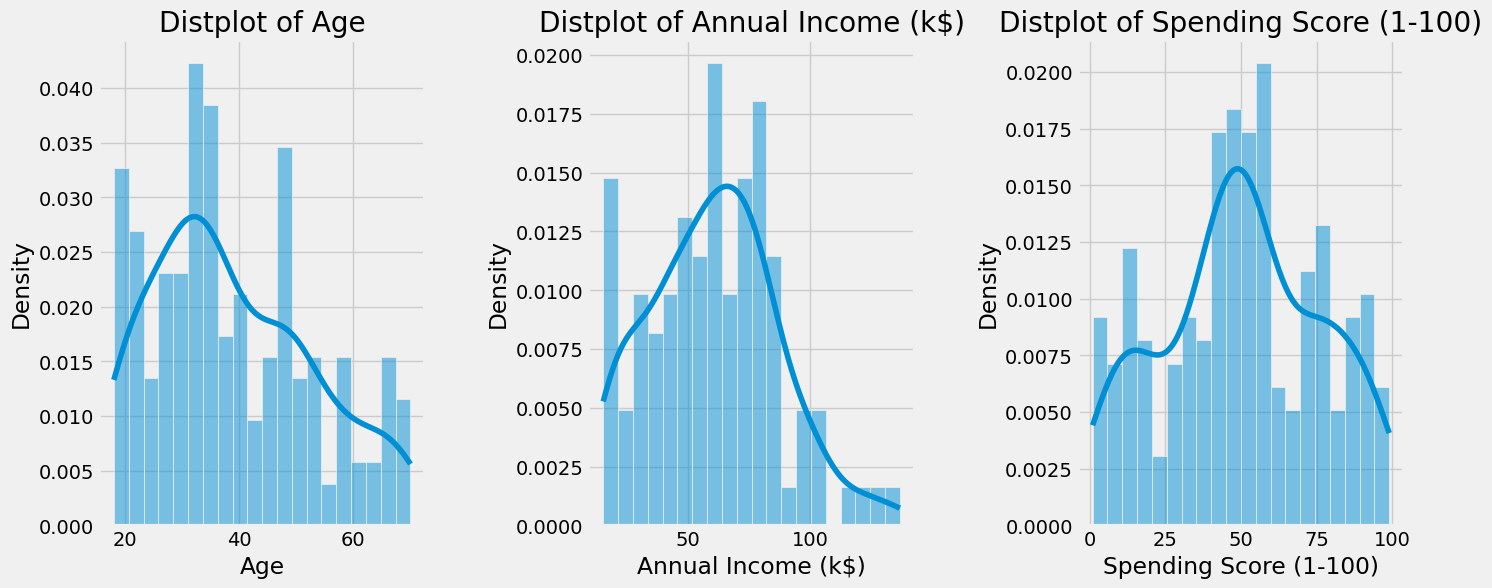

In [3]:
print("Hồng Kim Dung - 6451071009")
plt.style.use("fivethirtyeight")
plt.figure(1, figsize=(15, 6))
n = 0
for x in ["Age", "Annual Income (k$)", "Spending Score (1-100)"]:
    n += 1
    plt.subplot(1, 3, n)
    plt.subplots_adjust(hspace=0.5, wspace=0.5)
    sns.histplot(data[x], bins=20, kde=True, stat="density")
    plt.title("Distplot of {}".format(x))
plt.show()

## Câu 3 - Thống kê số mẫu theo Giới tính

Hồng Kim Dung - 6451071009
Gender
Female    112
Male       88
Name: count, dtype: int64


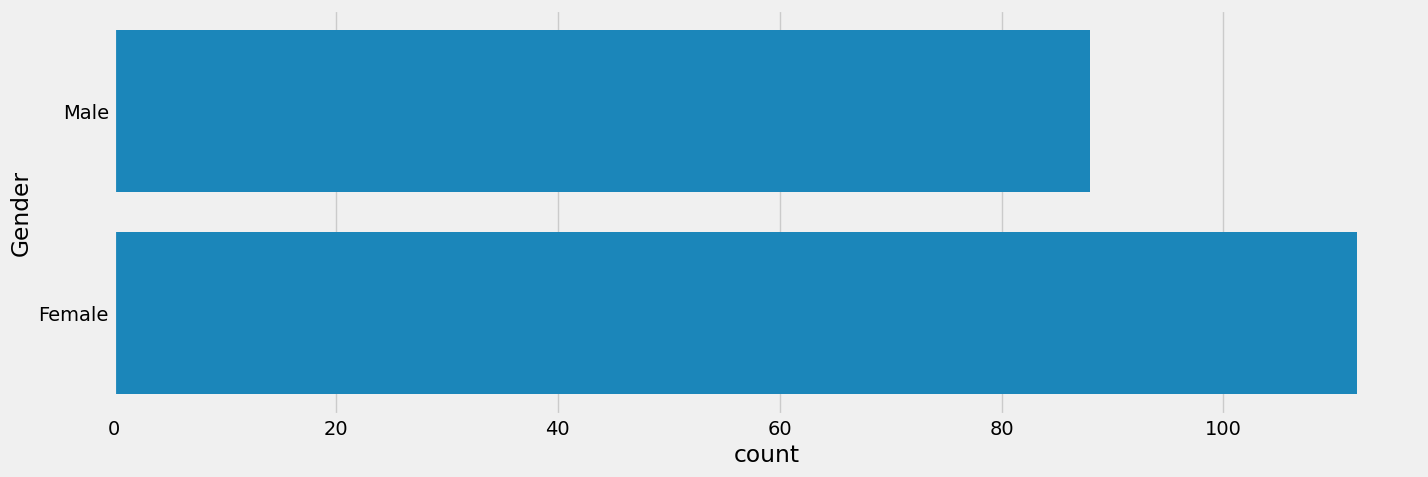

In [4]:
print("Hồng Kim Dung - 6451071009")
print(data["Gender"].value_counts())

plt.figure(1, figsize=(15, 5))
sns.countplot(y="Gender", data=data)
plt.show()

## Câu 4 - Scatter: Tuổi và Thu nhập hằng năm theo Giới tính

Hồng Kim Dung - 6451071009


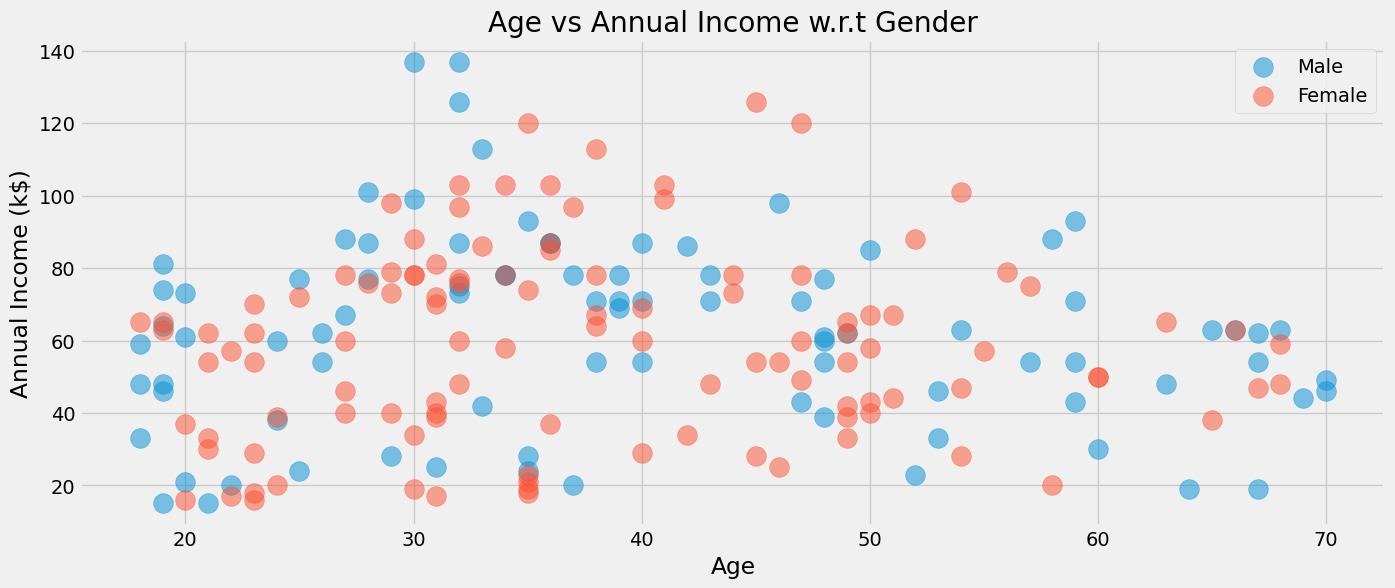

In [5]:
print("Hồng Kim Dung - 6451071009")
plt.figure(1, figsize=(15, 6))
for gender in ["Male", "Female"]:
    plt.scatter(x="Age", y="Annual Income (k$)", data=data[data["Gender"] == gender],
                s=200, alpha=0.5, label=gender)
plt.xlabel("Age"), plt.ylabel("Annual Income (k$)")
plt.title("Age vs Annual Income w.r.t Gender")
plt.legend()
plt.show()

## Câu 5 - Scatter: Thu nhập hằng năm và Số điểm mua sắm theo Giới tính

Hồng Kim Dung - 6451071009


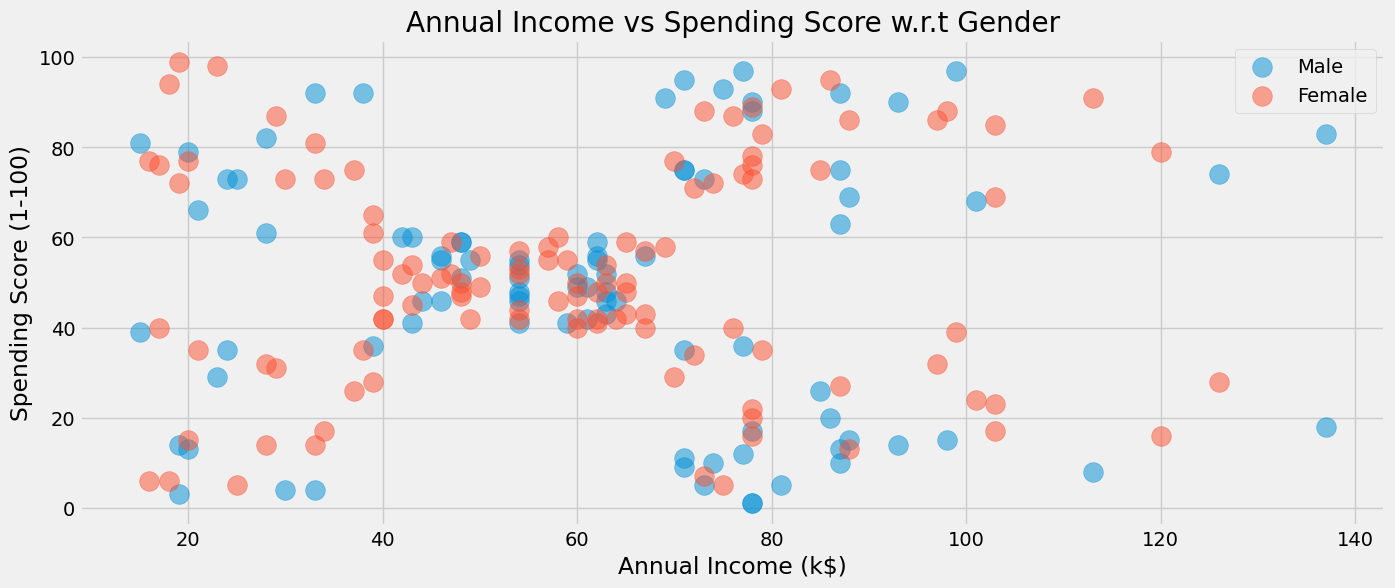

In [6]:
print("Hồng Kim Dung - 6451071009")
plt.figure(1, figsize=(15, 6))
for gender in ["Male", "Female"]:
    plt.scatter(x="Annual Income (k$)", y="Spending Score (1-100)", data=data[data["Gender"] == gender],
                s=200, alpha=0.5, label=gender)
plt.xlabel("Annual Income (k$)"), plt.ylabel("Spending Score (1-100)")
plt.title("Annual Income vs Spending Score w.r.t Gender")
plt.legend()
plt.show()

## Câu 6 - Tuổi và Số điểm mua sắm: Elbow method + k-Means

Hồng Kim Dung - 6451071009


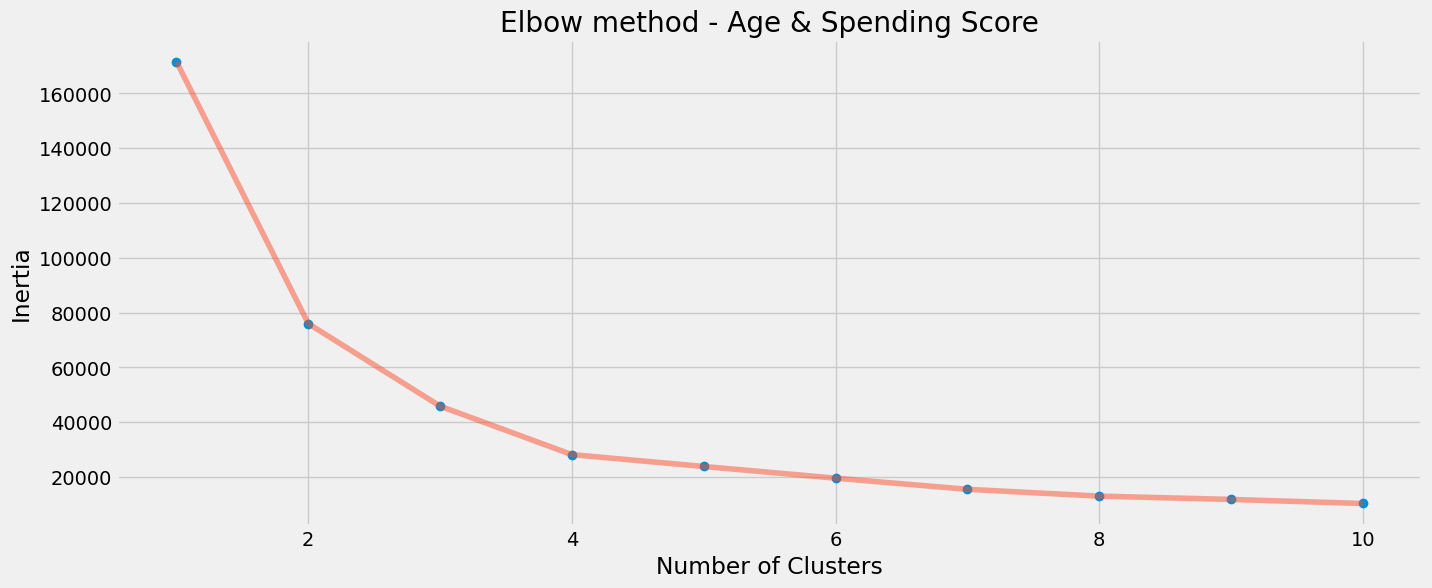

Số cụm k = 4
Tâm cụm:
 [[55.70833333 48.22916667]
 [43.29166667 15.02083333]
 [27.61702128 49.14893617]
 [30.1754386  82.35087719]]


In [7]:
print("Hồng Kim Dung - 6451071009")
X1 = data[["Age", "Spending Score (1-100)"]].iloc[:, :].values

inertia = []
for n in range(1, 11):
    algorithm = KMeans(n_clusters=n, init="random", n_init=10, random_state=42)
    algorithm.fit(X1)
    inertia.append(algorithm.inertia_)

plt.figure(1, figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia, "o")
plt.plot(np.arange(1, 11), inertia, "-", alpha=0.5)
plt.xlabel("Number of Clusters"), plt.ylabel("Inertia")
plt.title("Elbow method - Age & Spending Score")
plt.show()

# Từ biểu đồ Elbow, chọn số cụm tối ưu k = 4
algorithm = KMeans(n_clusters=4, init="random", n_init=10, random_state=42)
algorithm.fit(X1)
labels1 = algorithm.labels_
centroids1 = algorithm.cluster_centers_
print("Số cụm k = 4")
print("Tâm cụm:\n", centroids1)

## Câu 7 - Biểu diễn kết quả gom cụm (Tuổi, Số điểm mua sắm)

Hồng Kim Dung - 6451071009


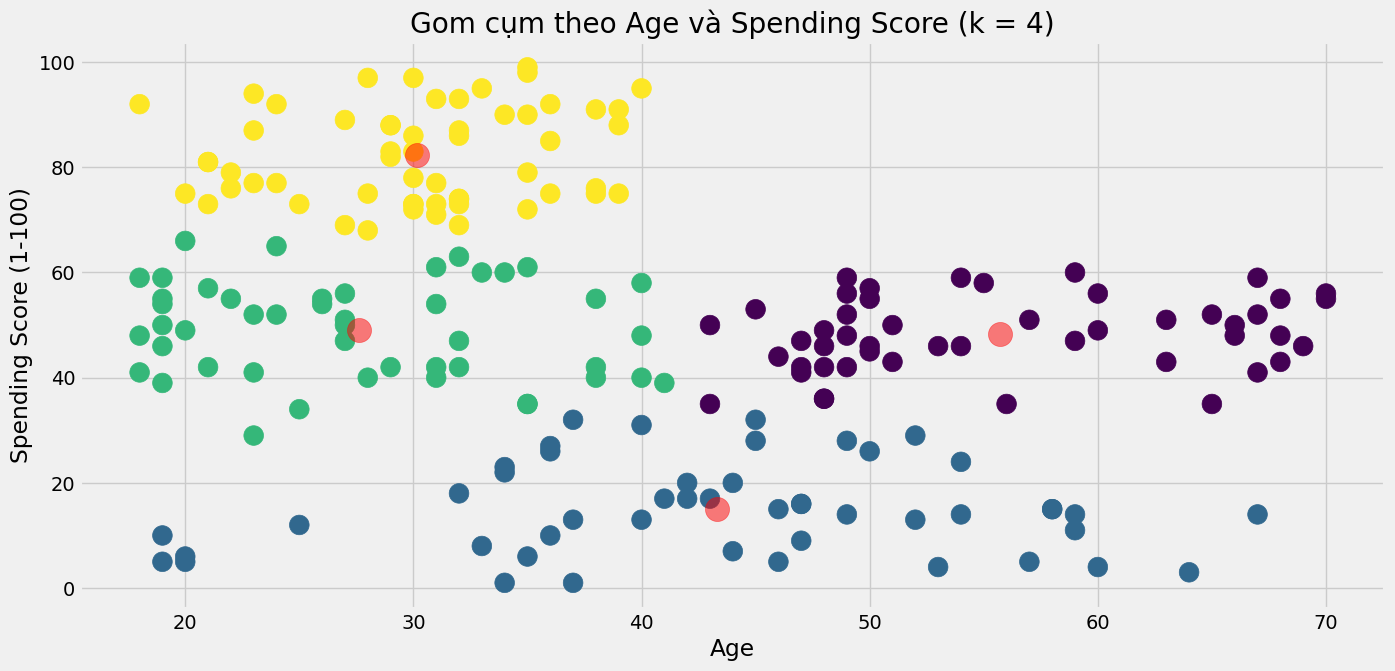

In [8]:
print("Hồng Kim Dung - 6451071009")
plt.figure(1, figsize=(15, 7))
plt.clf()
plt.scatter(x="Age", y="Spending Score (1-100)", data=data, c=labels1, s=200)
plt.scatter(x=centroids1[:, 0], y=centroids1[:, 1], s=300, c="red", alpha=0.5)
plt.ylabel("Spending Score (1-100)"), plt.xlabel("Age")
plt.title("Gom cụm theo Age và Spending Score (k = 4)")
plt.show()

## Câu 8 - Silhouette coefficient (Tuổi, Số điểm mua sắm)

In [9]:
print("Hồng Kim Dung - 6451071009")
score1 = metrics.silhouette_score(X1, labels1, metric="euclidean")
print("Silhouette coefficient (Age, Spending Score), k = 4:", score1)

Hồng Kim Dung - 6451071009
Silhouette coefficient (Age, Spending Score), k = 4: 0.49973941540141753


## Câu 9a - Thu nhập hằng năm và Số điểm mua sắm (câu 6, 7, 8)

Hồng Kim Dung - 6451071009


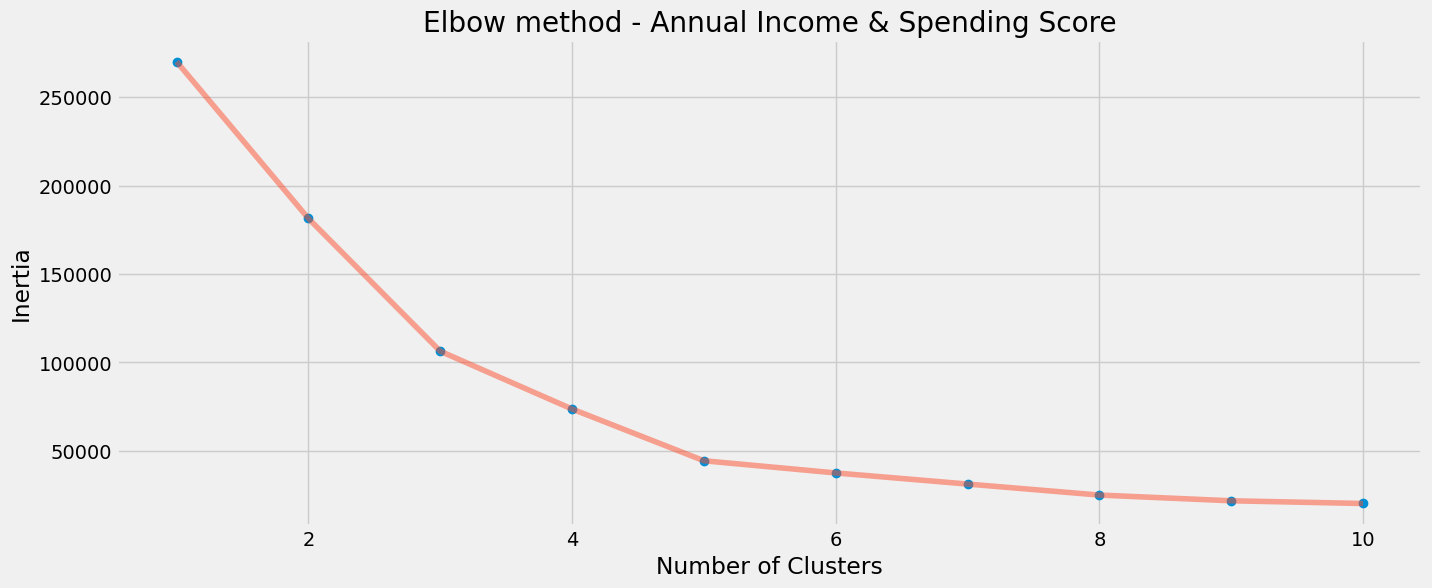

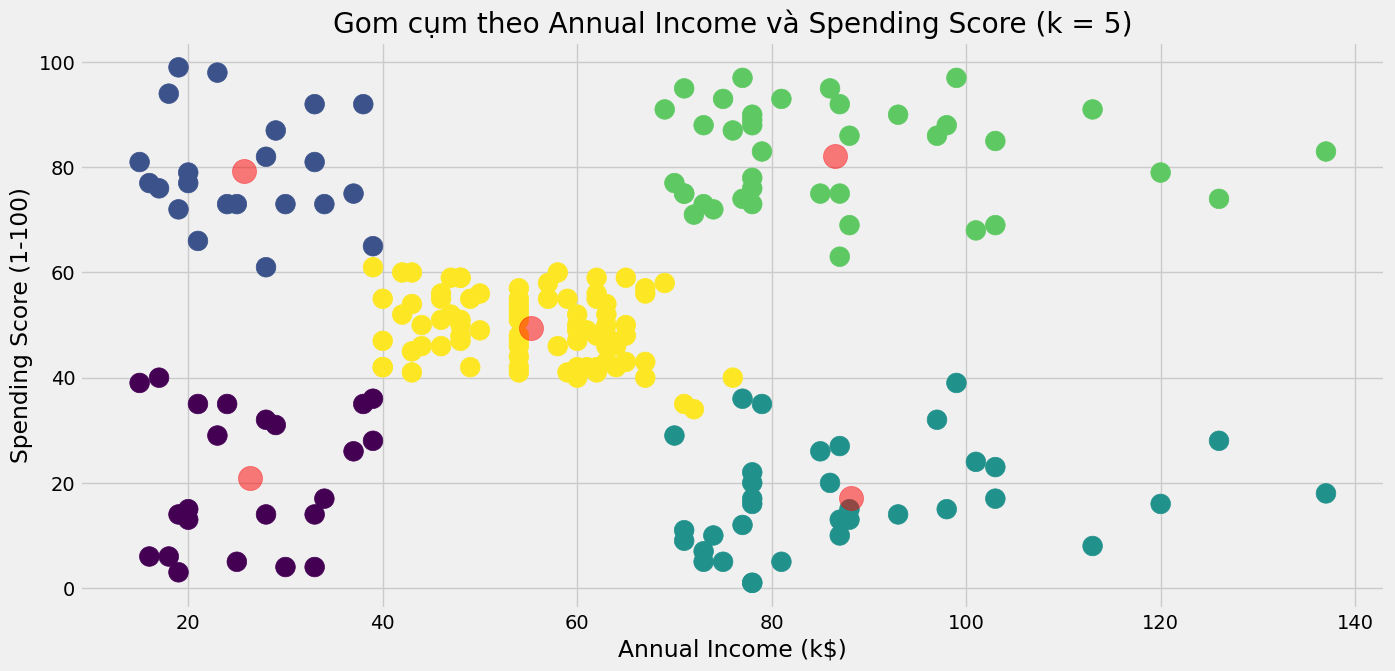

Silhouette coefficient (Annual Income, Spending Score), k = 5: 0.553931997444648


In [10]:
print("Hồng Kim Dung - 6451071009")
X2 = data[["Annual Income (k$)", "Spending Score (1-100)"]].values

# Câu 6: Elbow method
inertia2 = []
for n in range(1, 11):
    km = KMeans(n_clusters=n, init="random", n_init=10, random_state=42).fit(X2)
    inertia2.append(km.inertia_)

plt.figure(1, figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia2, "o")
plt.plot(np.arange(1, 11), inertia2, "-", alpha=0.5)
plt.xlabel("Number of Clusters"), plt.ylabel("Inertia")
plt.title("Elbow method - Annual Income & Spending Score")
plt.show()

# Từ biểu đồ Elbow, chọn k = 5
algorithm2 = KMeans(n_clusters=5, init="random", n_init=10, random_state=42)
algorithm2.fit(X2)
labels2 = algorithm2.labels_
centroids2 = algorithm2.cluster_centers_

# Câu 7: biểu diễn kết quả gom cụm
plt.figure(1, figsize=(15, 7))
plt.clf()
plt.scatter(x="Annual Income (k$)", y="Spending Score (1-100)", data=data, c=labels2, s=200)
plt.scatter(x=centroids2[:, 0], y=centroids2[:, 1], s=300, c="red", alpha=0.5)
plt.ylabel("Spending Score (1-100)"), plt.xlabel("Annual Income (k$)")
plt.title("Gom cụm theo Annual Income và Spending Score (k = 5)")
plt.show()

# Câu 8: Silhouette
score2 = metrics.silhouette_score(X2, labels2, metric="euclidean")
print("Silhouette coefficient (Annual Income, Spending Score), k = 5:", score2)

## Câu 9b - Tuổi, Thu nhập hằng năm và Số điểm mua sắm (câu 6, 7, 8 + biểu đồ 3D)

Hồng Kim Dung - 6451071009


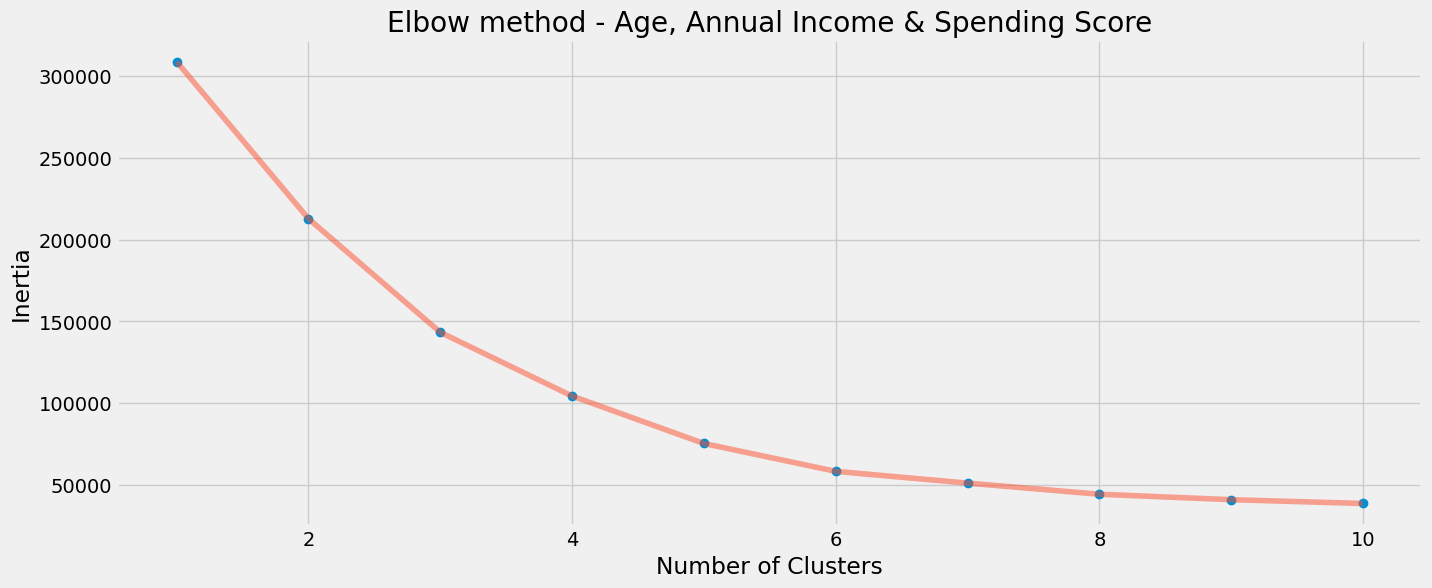

Silhouette coefficient (Age, Annual Income, Spending Score), k = 6: 0.4523566166018854


In [11]:
print("Hồng Kim Dung - 6451071009")
X3 = data[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].values

# Câu 6: Elbow method
inertia3 = []
for n in range(1, 11):
    km = KMeans(n_clusters=n, init="random", n_init=10, random_state=42).fit(X3)
    inertia3.append(km.inertia_)

plt.figure(1, figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia3, "o")
plt.plot(np.arange(1, 11), inertia3, "-", alpha=0.5)
plt.xlabel("Number of Clusters"), plt.ylabel("Inertia")
plt.title("Elbow method - Age, Annual Income & Spending Score")
plt.show()

# Từ biểu đồ Elbow và hệ số Silhouette, chọn k = 6
algorithm3 = KMeans(n_clusters=6, init="random", n_init=10, random_state=42)
algorithm3.fit(X3)
labels3 = algorithm3.labels_

# Câu 8: Silhouette
score3 = metrics.silhouette_score(X3, labels3, metric="euclidean")
print("Silhouette coefficient (Age, Annual Income, Spending Score), k = 6:", score3)

# Câu 7: biểu đồ 3D
data["label3"] = labels3
trace1 = go.Scatter3d(
    x=data["Age"],
    y=data["Spending Score (1-100)"],
    z=data["Annual Income (k$)"],
    mode="markers",
    marker=dict(color=data["label3"], size=6, opacity=0.8),
)
layout = go.Layout(
    title="Clusters",
    scene=dict(xaxis=dict(title="Age"),
               yaxis=dict(title="Spending Score"),
               zaxis=dict(title="Annual Income")),
)
fig = go.Figure(data=[trace1], layout=layout)
fig.show()